<a href="https://colab.research.google.com/github/zainaBanglekar/CSL701-Roll_No_-CS03_Machine-Learning-Lab/blob/main/Experiments%20and%20Mini-Project/ML_Experiment_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Machine Learning Experiment Number 3

**Aim** : To implement a Multiple Linear Regression model from scratch using NumPy matrix operations to predict the selling price of used cars using multiple features from the CarDekho Used Car Dataset.


**Learning Outcomes**
•	Understand the working principle of Multiple Linear Regression.

•	Perform data preprocessing and feature engineering.

•	Convert categorical data into numerical features.

•	Standardize numerical features.

•	Implement the Ordinary Least Squares method using matrix operations.

•	Train and test a regression model without using a ready-made regression function.

•	Evaluate and interpret regression performance using RSS and R².

•	Understand the effect of individual features on the predicted price.



\### Dataset

Use the **CarDekho Used Car Dataset** (`car data.csv`). [CarDekho Used Car Dataset](https://www.kaggle.com/datasets/manishkr1754/cardekho-used-car-data)

Explain meaning of each attribute in this dataset in below comment section :


Here, **Selling_Price** is the target variable.





\# Software/Tools Required

- Python 3.x
- Google Colab / Jupyter Notebook
- NumPy
- Matplotlib

---


### Task 1: Set Up the Python Environment**

- Create a new Google Colab notebook.
- Import **NumPy** for numerical and matrix operations.
- Import **Matplotlib** for data visualization.
- Do not use ready-made machine-learning regression functions such as `LinearRegression()` from Scikit-learn.
- The regression model must be implemented using matrix operations.

---

In [3]:
# Import required libraries

import numpy as np
import matplotlib.pyplot as plt

print("NumPy version:", np.__version__)
print("Matplotlib version:", plt.matplotlib.__version__)


NumPy version: 2.1.3
Matplotlib version: 3.10.0


## Task 2: Load and Inspect the Dataset

- Download the `car data.csv` file.
- Upload the dataset to Google Colab.
- Load the dataset into Python.
- Display the first few records.
- Determine the number of rows and columns.
- Identify the numerical and categorical attributes.
- Separate `Selling_Price` as the target variable.

---

In [6]:
from google.colab import files

uploaded = files.upload()
import pandas as pd

# Load the uploaded CSV file
df = pd.read_csv("cardekho_dataset (1).csv")

# Display the first 5 records
df.head()
# Get number of rows and columns
rows, columns = df.shape

print("Number of rows:", rows)
print("Number of columns:", columns)
# Display data types
print(df.dtypes)
# Numerical attributes
numerical_attributes = df.select_dtypes(include=np.number).columns.tolist()

# Categorical attributes
categorical_attributes = df.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical attributes:")
print(numerical_attributes)

print("\nCategorical attributes:")
print(categorical_attributes)
# Target variable
y = df["selling_price"]

# Input features
X = df.drop("selling_price", axis=1)

print("Target variable:")
print(y.head())

print("\nInput features:")
print(X.head())

Saving cardekho_dataset.csv to cardekho_dataset (3).csv
Number of rows: 15411
Number of columns: 14
Unnamed: 0             int64
car_name              object
brand                 object
model                 object
vehicle_age            int64
km_driven              int64
seller_type           object
fuel_type             object
transmission_type     object
mileage              float64
engine                 int64
max_power            float64
seats                  int64
selling_price          int64
dtype: object
Numerical attributes:
['Unnamed: 0', 'vehicle_age', 'km_driven', 'mileage', 'engine', 'max_power', 'seats', 'selling_price']

Categorical attributes:
['car_name', 'brand', 'model', 'seller_type', 'fuel_type', 'transmission_type']
Target variable:
0    120000
1    550000
2    215000
3    226000
4    570000
Name: selling_price, dtype: int64

Input features:
   Unnamed: 0       car_name    brand     model  vehicle_age  km_driven  \
0           0    Maruti Alto   Maruti      Alto

## Task 3: Check and Handle Missing Data

- Check every attribute for missing or null values.
- Count the number of missing values in each column.
- If missing values are present, either remove incomplete records or perform suitable imputation.
- Verify that the final dataset does not contain missing values.
- Record the preprocessing method used.

---

In [7]:
# Check the number of missing values in each column
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)
print("Total missing values:", df.isnull().sum().sum())
# Remove rows containing missing values
df = df.dropna().copy()

print("Dataset shape after removing missing values:", df.shape)
# Verify missing values after preprocessing
print("Missing values after preprocessing:")
print(df.isnull().sum())

print("\nTotal missing values after preprocessing:",
      df.isnull().sum().sum())


Missing values in each column:
Unnamed: 0           0
car_name             0
brand                0
model                0
vehicle_age          0
km_driven            0
seller_type          0
fuel_type            0
transmission_type    0
mileage              0
engine               0
max_power            0
seats                0
selling_price        0
dtype: int64
Total missing values: 0
Dataset shape after removing missing values: (15411, 14)
Missing values after preprocessing:
Unnamed: 0           0
car_name             0
brand                0
model                0
vehicle_age          0
km_driven            0
seller_type          0
fuel_type            0
transmission_type    0
mileage              0
engine               0
max_power            0
seats                0
selling_price        0
dtype: int64

Total missing values after preprocessing: 0


## Task 4: Select and Prepare Features

- Examine all available attributes.
- Decide how `Car_Name` should be handled.
- Select meaningful predictor variables for the regression model.
- Create the predictor matrix $X$ and target vector $y$.
- Record the final list of features selected for the model.

---

In [9]:
# Display all column names
print("Available attributes:")
print(df.columns.tolist())

# Display data types
print("\nData types:")
print(df.dtypes)
# Select predictor variables
features = [
    "vehicle_age", # Replaces "Year"
    "km_driven", # Replaces "Kms_Driven"
    "seller_type", # Replaces "Selling_type"
    "fuel_type", # Replaces "Fuel_Type"
    "transmission_type", # Replaces "Transmission"
    "mileage", # Added relevant numerical feature
    "engine", # Added relevant numerical feature
    "max_power", # Added relevant numerical feature
    "seats" # Added relevant numerical feature
]

# Note: "Present_Price" and "Owner" from the original list are not in the DataFrame and have been removed.

X = df[features].copy()

# Target variable
y = df["selling_price"].copy() # Corrected to lowercase 's' for 'selling_price'

print("Selected features:")
print(features)

print("\nPredictor data:")
print(X.head())

print("\nTarget data:")
print(y.head())
# Convert categorical variables into dummy variables
# Updated column names for get_dummies
X = pd.get_dummies(
    X,
    columns=["fuel_type", "seller_type", "transmission_type"],
    drop_first=True,
    dtype=int
)

print("Final predictor matrix:")
print(X.head())

print("\nShape of X:", X.shape)
print("Shape of y:", y.shape)
print("Final data types:")
print(X.dtypes)

print("\nAre all predictors numerical?")
print(X.dtypes.apply(lambda dtype: np.issubdtype(dtype, np.number)).all())
print("Final features used in the regression model:")
for i, feature in enumerate(X.columns, start=1):
    print(f"{i}. {feature}")

Available attributes:
['Unnamed: 0', 'car_name', 'brand', 'model', 'vehicle_age', 'km_driven', 'seller_type', 'fuel_type', 'transmission_type', 'mileage', 'engine', 'max_power', 'seats', 'selling_price']

Data types:
Unnamed: 0             int64
car_name              object
brand                 object
model                 object
vehicle_age            int64
km_driven              int64
seller_type           object
fuel_type             object
transmission_type     object
mileage              float64
engine                 int64
max_power            float64
seats                  int64
selling_price          int64
dtype: object
Selected features:
['vehicle_age', 'km_driven', 'seller_type', 'fuel_type', 'transmission_type', 'mileage', 'engine', 'max_power', 'seats']

Predictor data:
   vehicle_age  km_driven seller_type fuel_type transmission_type  mileage  \
0            9     120000  Individual    Petrol            Manual    19.70   
1            5      20000  Individual    Petrol   

## Task 5: Encode Categorical Variables

Identify the categorical variables:

- `Fuel_Type`
- `Seller_Type`
- `Transmission`

Perform the following:

- Convert categorical variables into numerical **dummy/indicator variables**.
- Verify that all predictors are numerical after encoding.
- Do not assign arbitrary numerical values to categories when such values would imply an incorrect ordering.
- Display the transformed dataset.

---

In [10]:
# ==========================================
# Task 5: Encode Categorical Variables
# ==========================================

# Identify categorical variables that exist in the dataset
categorical_features = [
    col for col in ["Fuel_Type", "Seller_Type", "Selling_type", "Transmission"]
    if col in df.columns
]

print("Categorical variables:")
print(categorical_features)

# Create predictor dataset
X_encoded = X.copy()

# One-hot encode categorical variables
X_encoded = pd.get_dummies(
    X_encoded,
    columns=categorical_features,
    drop_first=True,
    dtype=int
)

# Display transformed dataset
print("\nTransformed dataset:")
display(X_encoded)

# Verify data types
print("\nData types after encoding:")
print(X_encoded.dtypes)

# Verify all predictors are numerical
all_numeric = X_encoded.dtypes.apply(
    lambda dtype: np.issubdtype(dtype, np.number)
).all()

print("\nAre all predictors numerical?", all_numeric)

# Set final predictor matrix
X = X_encoded.copy()

print("\nFinal X shape:", X.shape)


Categorical variables:
[]

Transformed dataset:


,vehicle_age,km_driven,mileage,engine,max_power,seats,fuel_type_Diesel,fuel_type_Electric,fuel_type_LPG,fuel_type_Petrol,seller_type_Individual,seller_type_Trustmark Dealer,transmission_type_Manual
0,9,120000,19.70,796,46.30,5,0,0,0,1,1,0,1
1,5,20000,18.90,1197,82.00,5,0,0,0,1,1,0,1
2,11,60000,17.00,1197,80.00,5,0,0,0,1,1,0,1
3,9,37000,20.92,998,67.10,5,0,0,0,1,1,0,1
4,6,30000,22.77,1498,98.59,5,1,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
15406,9,10723,19.81,1086,68.05,5,0,0,0,1,0,0,1
15407,2,18000,17.50,1373,91.10,7,0,0,0,1,0,0,1
15408,6,67000,21.14,1498,103.52,5,1,0,0,0,0,0,1
15409,5,3800000,16.00,2179,140.00,7,1,0,0,0,0,0,1



Data types after encoding:
vehicle_age                       int64
km_driven                         int64
mileage                         float64
engine                            int64
max_power                       float64
seats                             int64
fuel_type_Diesel                  int64
fuel_type_Electric                int64
fuel_type_LPG                     int64
fuel_type_Petrol                  int64
seller_type_Individual            int64
seller_type_Trustmark Dealer      int64
transmission_type_Manual          int64
dtype: object

Are all predictors numerical? True

Final X shape: (15411, 13)


## Task 6: Perform Feature Engineering

Create a new feature called `Car_Age`.

Calculate it using:

\[
Car\_Age = Current Year - Year
\]

Perform the following:

- Create the `Car_Age` column.
- Display several values of the newly created feature.
- Verify that the calculated ages are reasonable.
- Decide whether the original `Year` feature should be retained.
- Provide a reason for your decision.

---

In [12]:
# ==========================================
# Task 6: Feature Engineering
# ==========================================

# Current year (this variable is not used directly as 'Year' column is not available)
current_year = 2026

# The dataset already contains 'vehicle_age' which represents the age of the car.
# We will use this existing feature as 'Car_Age'.

# Create 'Car_Age' in the main DataFrame df from 'vehicle_age'
# This ensures df also has a 'Car_Age' column as per task instructions.
df["Car_Age"] = df["vehicle_age"]
print("Created 'Car_Age' from 'vehicle_age' in df.")

# Display several calculated values
# Display 'vehicle_age' as it was the source, and 'Car_Age' as the new feature.
print("\nVehicle_age and calculated Car_Age:")
display(df[["vehicle_age", "Car_Age"]].head(10))

# Check whether ages are reasonable
print("\nCar_Age statistics:")
print(df["Car_Age"].describe())

# Check for invalid negative ages
negative_ages = (df["Car_Age"] < 0).sum()

print("\nNumber of negative car ages:", negative_ages)
print("Minimum car age:", df["Car_Age"].min())
print("Maximum car age:", df["Car_Age"].max())

# Update the X matrix:
# Rename 'vehicle_age' to 'Car_Age' in X to avoid duplicate features and match task naming.
if "vehicle_age" in X.columns:
    X = X.rename(columns={"vehicle_age": "Car_Age"})
    print("\nRenamed 'vehicle_age' to 'Car_Age' in X.")
elif "Car_Age" not in X.columns:
    # Fallback, though less likely given previous steps: add Car_Age if it doesn't exist
    X["Car_Age"] = df["Car_Age"]
    print("\nAdded 'Car_Age' to X from df.")

# Remove 'Year' because 'Car_Age' contains equivalent information (or is the same as 'vehicle_age').
# This line is kept for robustness, but 'Year' is not expected to be in X.
X = X.drop(columns=["Year"], errors="ignore")

print("\nFinal predictor features:")
print(X.columns.tolist())

Created 'Car_Age' from 'vehicle_age' in df.

Vehicle_age and calculated Car_Age:


,vehicle_age,Car_Age
0,9,9
1,5,5
2,11,11
3,9,9
4,6,6
5,8,8
6,8,8
7,3,3
8,2,2
9,4,4



Car_Age statistics:
count    15411.000000
mean         6.036338
std          3.013291
min          0.000000
25%          4.000000
50%          6.000000
75%          8.000000
max         29.000000
Name: Car_Age, dtype: float64

Number of negative car ages: 0
Minimum car age: 0
Maximum car age: 29

Renamed 'vehicle_age' to 'Car_Age' in X.

Final predictor features:
['Car_Age', 'km_driven', 'mileage', 'engine', 'max_power', 'seats', 'fuel_type_Diesel', 'fuel_type_Electric', 'fuel_type_LPG', 'fuel_type_Petrol', 'seller_type_Individual', 'seller_type_Trustmark Dealer', 'transmission_type_Manual']


## Task 7: Perform Exploratory Data Analysis

Perform basic exploratory data analysis using Matplotlib.

- Create a scatter plot of `Present_Price` versus `Selling_Price`.
- Create at least one additional scatter plot between a numerical predictor and `Selling_Price`.
- Label the axes appropriately.
- Add suitable titles to the plots.
- Observe the direction and approximate strength of the relationships.
- Record your observations.

---

Numerical columns:
['Unnamed: 0', 'vehicle_age', 'km_driven', 'mileage', 'engine', 'max_power', 'seats', 'selling_price', 'Car_Age']


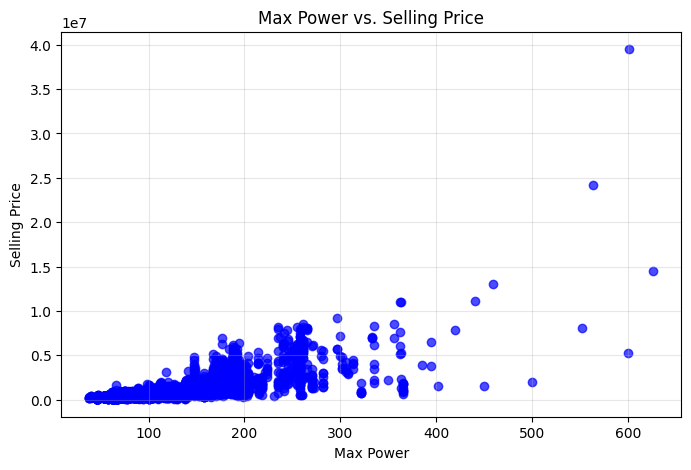

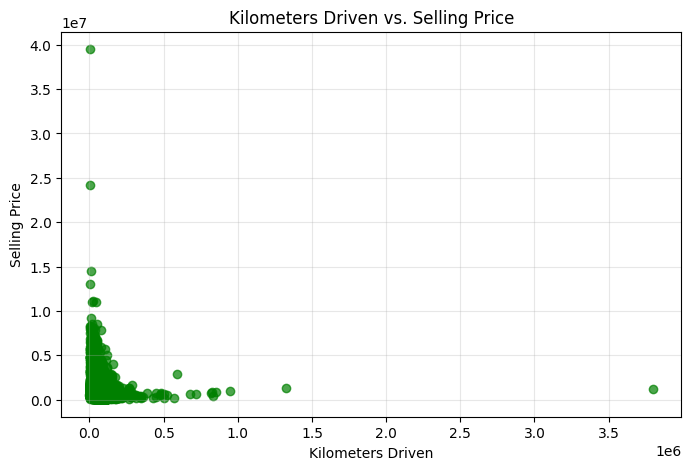

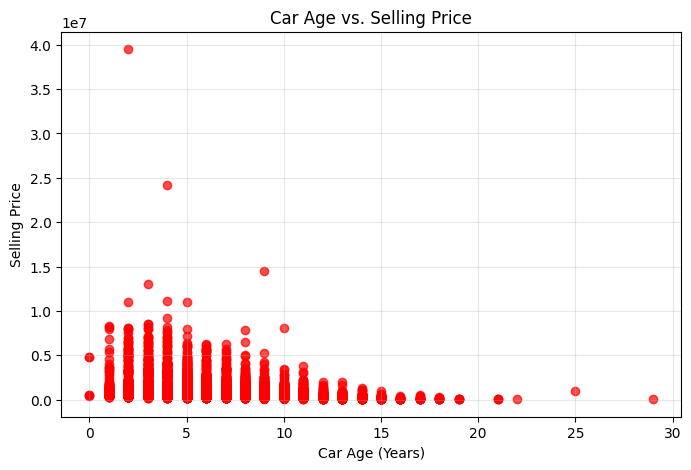

CORRELATION WITH SELLING PRICE
Max_Power: 0.75
km_driven: -0.08
Car_Age: -0.242


In [14]:
# ==========================================
# TASK 7: EXPLORATORY DATA ANALYSIS
# ==========================================

import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------
# 1. Display numerical variables
# ------------------------------------------

print("Numerical columns:")
print(df.select_dtypes(include=np.number).columns.tolist())


# ------------------------------------------
# 2. Max_Power vs Selling_Price (substituted for Present_Price)
# ------------------------------------------

plt.figure(figsize=(8, 5))

plt.scatter(
    df["max_power"],
    df["selling_price"],
    color="blue",
    alpha=0.7
)

plt.xlabel("Max Power")
plt.ylabel("Selling Price")
plt.title("Max Power vs. Selling Price")
plt.grid(True, alpha=0.3)

plt.show()


# ------------------------------------------
# 3. km_driven vs Selling_Price (corrected Kms_Driven)
# ------------------------------------------

plt.figure(figsize=(8, 5))

plt.scatter(
    df["km_driven"],
    df["selling_price"],
    color="green",
    alpha=0.7
)

plt.xlabel("Kilometers Driven")
plt.ylabel("Selling Price")
plt.title("Kilometers Driven vs. Selling Price")
plt.grid(True, alpha=0.3)

plt.show()


# ------------------------------------------
# 4. Car_Age vs Selling_Price
# ------------------------------------------

plt.figure(figsize=(8, 5))

plt.scatter(
    df["Car_Age"],
    df["selling_price"],
    color="red",
    alpha=0.7
)

plt.xlabel("Car Age (Years)")
plt.ylabel("Selling Price")
plt.title("Car Age vs. Selling Price")
plt.grid(True, alpha=0.3)

plt.show()


# ------------------------------------------
# 5. Calculate correlations
# ------------------------------------------

correlation_max_power = df["max_power"].corr(
    df["selling_price"]
)

correlation_km_driven = df["km_driven"].corr(
    df["selling_price"]
)

correlation_car_age = df["Car_Age"].corr(
    df["selling_price"]
)

print("==========================================")
print("CORRELATION WITH SELLING PRICE")
print("==========================================")

print(
    "Max_Power:", # Updated for max_power
    round(correlation_max_power, 3)
)

print(
    "km_driven:", # Corrected for km_driven
    round(correlation_km_driven, 3)
)

print(
    "Car_Age:",
    round(correlation_car_age, 3)
)

## Task 8: Standardize Numerical Features

Identify the numerical predictors that need to be standardized.

Use the following standardization equation:

\[
z = ($x$-$\mu$)/$\sigma$
\]

where:

- $x$ = original feature value
- $\mu$ = mean of the feature
- $\sigma$ = standard deviation of the feature

Perform the following:

- Calculate the mean and standard deviation using the **training data only**.
- Standardize the training features.
- Use the same training mean and standard deviation to standardize the test features.
- Do not standardize the target variable `Selling_Price`.

---

In [16]:
# ==========================================
# TASK 8: STANDARDIZE NUMERICAL FEATURES
# ==========================================

import numpy as np

# ------------------------------------------
# 1. Prepare X and y
# ------------------------------------------

X = X.reset_index(drop=True)
y = y.reset_index(drop=True)


# ------------------------------------------
# 2. Train-test split
# ------------------------------------------

np.random.seed(42)

n = len(X)

indices = np.random.permutation(n)

train_size = int(0.80 * n)

train_indices = indices[:train_size]
test_indices = indices[train_size:]

X_train = X.iloc[train_indices].copy()
X_test = X.iloc[test_indices].copy()

y_train = y.iloc[train_indices].copy()
y_test = y.iloc[test_indices].copy()

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


# ------------------------------------------
# 3. Identify numerical features
# ------------------------------------------

numerical_features = [
    "Car_Age",
    "km_driven",
    "mileage",
    "engine",
    "max_power",
    "seats"
]

print("\nNumerical features to standardize:")
print(numerical_features)


# ------------------------------------------
# 4. Calculate training mean and std
# ------------------------------------------

train_means = X_train[numerical_features].mean()
train_stds = X_train[numerical_features].std()

print("\nTraining means:")
print(train_means)

print("\nTraining standard deviations:")
print(train_stds)


# ------------------------------------------
# 5. Standardize training features
# ------------------------------------------

X_train[numerical_features] = (
    X_train[numerical_features] - train_means
) / train_stds


# ------------------------------------------
# 6. Standardize test features
#    using TRAINING statistics
# ------------------------------------------

X_test[numerical_features] = (
    X_test[numerical_features] - train_means
) / train_stds


# ------------------------------------------
# 7. Display standardized data
# ------------------------------------------

print("\nStandardized training features:")
display(X_train.head())

print("\nStandardized test features:")
display(X_test.head())


# ------------------------------------------
# 8. Verify training standardization
# ------------------------------------------

print("\nTraining means after standardization:")
print(X_train[numerical_features].mean())

print("\nTraining standard deviations after standardization:")
print(X_train[numerical_features].std())


# ------------------------------------------
# 9. Verify target was NOT standardized
# ------------------------------------------

print("\nTraining target values:")
print(y_train.head())

print("\nTest target values:")
print(y_test.head())

Training samples: 12328
Testing samples: 3083

Numerical features to standardize:
['Car_Age', 'km_driven', 'mileage', 'engine', 'max_power', 'seats']

Training means:
Car_Age          6.032446
km_driven    55692.819598
mileage         19.691552
engine        1485.037395
max_power      100.516747
seats            5.326249
dtype: float64

Training standard deviations:
Car_Age          3.018870
km_driven    54473.163748
mileage          4.172802
engine         518.296985
max_power       42.745688
seats            0.809603
dtype: float64

Standardized training features:


,Car_Age,km_driven,mileage,engine,max_power,seats,fuel_type_Diesel,fuel_type_Electric,fuel_type_LPG,fuel_type_Petrol,seller_type_Individual,seller_type_Trustmark Dealer,transmission_type_Manual
3334,1.976751,0.317719,0.160192,-0.555738,-0.505706,-0.402974,0,0,0,1,0,0,1
10928,-0.673248,0.042354,1.844911,-0.457339,-0.620337,-0.402974,1,0,0,0,1,0,1
2518,0.320502,0.739946,0.258447,-0.457339,-0.275039,2.067371,1,0,0,0,0,0,1
11322,-1.666997,-0.939781,-0.309517,0.025010,0.440588,-0.402974,0,0,0,1,0,0,0
9394,1.645501,0.115785,0.002025,-1.329426,-1.268356,-0.402974,0,0,0,1,0,0,1



Standardized test features:


,Car_Age,km_driven,mileage,engine,max_power,seats,fuel_type_Diesel,fuel_type_Electric,fuel_type_LPG,fuel_type_Petrol,seller_type_Individual,seller_type_Trustmark Dealer,transmission_type_Manual
15384,-1.004497,-0.563448,-2.322552,1.279117,1.625503,-0.402974,1,0,0,0,0,0,0
147,0.651752,0.409508,-0.752864,0.931826,1.099368,-0.402974,1,0,0,0,0,0,0
1668,0.320502,0.124964,1.320084,-0.457339,-0.620337,-0.402974,1,0,0,0,0,0,1
11280,-0.341998,-0.563448,1.348841,-0.553809,-0.550155,0.832199,1,0,0,0,0,0,1
13650,-1.004497,-0.618521,-0.357446,-0.551879,-0.276443,-0.402974,0,0,0,1,0,0,0



Training means after standardization:
Car_Age     -1.786731e-17
km_driven    3.342917e-17
mileage     -1.809786e-16
engine       2.132550e-17
max_power    7.665654e-17
seats       -1.083566e-16
dtype: float64

Training standard deviations after standardization:
Car_Age      1.0
km_driven    1.0
mileage      1.0
engine       1.0
max_power    1.0
seats        1.0
dtype: float64

Training target values:
3334      190000
10928     600000
2518      665000
11322    1570000
9394      160000
Name: selling_price, dtype: int64

Test target values:
15384    4450000
147      1290000
1668      485000
11280     400000
13650     800000
Name: selling_price, dtype: int64


## Task 9: Split the Dataset

Divide the dataset into training and testing subsets.

- Use an **80:20 train-test ratio**.
- Randomly select the observations.
- Set a fixed random seed to make the experiment reproducible.
- Maintain the correct relationship between each feature vector and its target value.
- Display the number of observations in the training and testing sets.

---

In [17]:
# ==========================================
# TASK 9: SPLIT THE DATASET
# ==========================================

# Reset indices so X and y are aligned
X = X.reset_index(drop=True)
y = y.reset_index(drop=True)

# Set fixed random seed
np.random.seed(42)

# Total observations
n = len(X)

# Randomly shuffle indices
indices = np.random.permutation(n)

# 80% training data
train_size = int(0.80 * n)

# Create train and test indices
train_indices = indices[:train_size]
test_indices = indices[train_size:]

# Create training and testing feature matrices
X_train = X.iloc[train_indices].copy()
X_test = X.iloc[test_indices].copy()

# Create training and testing target vectors
y_train = y.iloc[train_indices].copy()
y_test = y.iloc[test_indices].copy()

# Display results
print("==========================================")
print("TRAIN-TEST SPLIT")
print("==========================================")

print("Total observations:", n)
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

print("\nTraining feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("\nTraining target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

# Verify feature-target alignment
print("\nFeature-target alignment:")
print("Training X and y indices match:",
      X_train.index.equals(y_train.index))

print("Testing X and y indices match:",
      X_test.index.equals(y_test.index))


TRAIN-TEST SPLIT
Total observations: 15411
Training observations: 12328
Testing observations: 3083

Training feature shape: (12328, 13)
Testing feature shape: (3083, 13)

Training target shape: (12328,)
Testing target shape: (3083,)

Feature-target alignment:
Training X and y indices match: True
Testing X and y indices match: True


## Task 10: Construct the Feature Matrix

Construct the matrices required for regression.

Create:

- $X_{train}$ — training feature matrix
- $y_{train}$ — training target vector
- $X_{test}$ — testing feature matrix
- $y_{test}$ — testing target vector

Verify:

- Number of rows in each matrix.
- Number of predictor columns.
- Shape of the training and testing matrices.

---

In [18]:
# ==========================================
# TASK 10: CONSTRUCT THE FEATURE MATRIX
# ==========================================

# Convert feature matrices to NumPy arrays
X_train = X_train.to_numpy(dtype=float)
X_test = X_test.to_numpy(dtype=float)

# Convert target vectors to NumPy arrays
y_train = y_train.to_numpy(dtype=float)
y_test = y_test.to_numpy(dtype=float)

# ------------------------------------------
# Display shapes
# ------------------------------------------

print("==========================================")
print("MATRIX SHAPES")
print("==========================================")

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)


# ------------------------------------------
# Number of observations
# ------------------------------------------

print("\n==========================================")
print("NUMBER OF OBSERVATIONS")
print("==========================================")

print("Training observations:", X_train.shape[0])
print("Testing observations:", X_test.shape[0])

print("Training target values:", y_train.shape[0])
print("Testing target values:", y_test.shape[0])


# ------------------------------------------
# Number of predictors
# ------------------------------------------

print("\n==========================================")
print("NUMBER OF PREDICTORS")
print("==========================================")

print("Training predictors:", X_train.shape[1])
print("Testing predictors:", X_test.shape[1])

print(
    "Same number of predictors:",
    X_train.shape[1] == X_test.shape[1]
)


# ------------------------------------------
# Verify rows match targets
# ------------------------------------------

print("\n==========================================")
print("ROW ALIGNMENT")
print("==========================================")

print(
    "X_train rows = y_train values:",
    X_train.shape[0] == y_train.shape[0]
)

print(
    "X_test rows = y_test values:",
    X_test.shape[0] == y_test.shape[0]
)


# ------------------------------------------
# Display sample values
# ------------------------------------------

print("\n==========================================")
print("SAMPLE DATA")
print("==========================================")

print("First 5 rows of X_train:")
print(X_train[:5])

print("\nFirst 5 values of y_train:")
print(y_train[:5])

print("\nFirst 5 rows of X_test:")
print(X_test[:5])

print("\nFirst 5 values of y_test:")
print(y_test[:5])


MATRIX SHAPES
X_train shape: (12328, 13)
y_train shape: (12328,)
X_test shape: (3083, 13)
y_test shape: (3083,)

NUMBER OF OBSERVATIONS
Training observations: 12328
Testing observations: 3083
Training target values: 12328
Testing target values: 3083

NUMBER OF PREDICTORS
Training predictors: 13
Testing predictors: 13
Same number of predictors: True

ROW ALIGNMENT
X_train rows = y_train values: True
X_test rows = y_test values: True

SAMPLE DATA
First 5 rows of X_train:
[[1.2000e+01 7.3000e+04 2.0360e+01 1.1970e+03 7.8900e+01 5.0000e+00
  0.0000e+00 0.0000e+00 0.0000e+00 1.0000e+00 0.0000e+00 0.0000e+00
  1.0000e+00]
 [4.0000e+00 5.8000e+04 2.7390e+01 1.2480e+03 7.4000e+01 5.0000e+00
  1.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 1.0000e+00 0.0000e+00
  1.0000e+00]
 [7.0000e+00 9.6000e+04 2.0770e+01 1.2480e+03 8.8760e+01 7.0000e+00
  1.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00
  1.0000e+00]
 [1.0000e+00 4.5000e+03 1.8400e+01 1.4980e+03 1.1935e+02 5.0000e+00
  0.0000

## Task 11: Add the Bias/Intercept Term

Add a leading column containing $1.0$ to both the training and testing feature matrices.

The resulting matrices should contain:

\[
X =
\begin{bmatrix}
1 & x_{11} & x_{12} & \cdots & x_{1p}\\
1 & x_{21} & x_{22} & \cdots & x_{2p}\\
\vdots & \vdots & \vdots & \ddots & \vdots\\
1 & x_{n1} & x_{n2} & \cdots & x_{np}
\end{bmatrix}
\]

Perform the following:

- Add the bias column.
- Verify the new matrix dimensions.
- Understand that the first column represents the intercept $\beta_0$.

---

In [19]:
# ==========================================
# TASK 11: ADD THE BIAS/INTERCEPT TERM
# ==========================================

# Create columns of 1.0
bias_train = np.ones((X_train.shape[0], 1))
bias_test = np.ones((X_test.shape[0], 1))

# Add bias as the first column
X_train_bias = np.hstack((bias_train, X_train))
X_test_bias = np.hstack((bias_test, X_test))

# ------------------------------------------
# Verify dimensions
# ------------------------------------------

print("==========================================")
print("MATRIX DIMENSIONS")
print("==========================================")

print("Original X_train:", X_train.shape)
print("Original X_test :", X_test.shape)

print("\nX_train with bias:", X_train_bias.shape)
print("X_test with bias :", X_test_bias.shape)


# ------------------------------------------
# Verify bias column
# ------------------------------------------

print("\n==========================================")
print("BIAS COLUMN VERIFICATION")
print("==========================================")

print("First 5 values of training bias column:")
print(X_train_bias[:5, 0])

print("\nFirst 5 values of testing bias column:")
print(X_test_bias[:5, 0])

print(
    "\nTraining bias column contains only 1.0:",
    np.all(X_train_bias[:, 0] == 1.0)
)

print(
    "Testing bias column contains only 1.0:",
    np.all(X_test_bias[:, 0] == 1.0)
)


# ------------------------------------------
# Display first few rows
# ------------------------------------------

print("\n==========================================")
print("X_train WITH BIAS")
print("==========================================")

print(X_train_bias[:5])

print("\n==========================================")
print("X_test WITH BIAS")
print("==========================================")

print(X_test_bias[:5])


MATRIX DIMENSIONS
Original X_train: (12328, 13)
Original X_test : (3083, 13)

X_train with bias: (12328, 14)
X_test with bias : (3083, 14)

BIAS COLUMN VERIFICATION
First 5 values of training bias column:
[1. 1. 1. 1. 1.]

First 5 values of testing bias column:
[1. 1. 1. 1. 1.]

Training bias column contains only 1.0: True
Testing bias column contains only 1.0: True

X_train WITH BIAS
[[1.0000e+00 1.2000e+01 7.3000e+04 2.0360e+01 1.1970e+03 7.8900e+01
  5.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 1.0000e+00 0.0000e+00
  0.0000e+00 1.0000e+00]
 [1.0000e+00 4.0000e+00 5.8000e+04 2.7390e+01 1.2480e+03 7.4000e+01
  5.0000e+00 1.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 1.0000e+00
  0.0000e+00 1.0000e+00]
 [1.0000e+00 7.0000e+00 9.6000e+04 2.0770e+01 1.2480e+03 8.8760e+01
  7.0000e+00 1.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00
  0.0000e+00 1.0000e+00]
 [1.0000e+00 1.0000e+00 4.5000e+03 1.8400e+01 1.4980e+03 1.1935e+02
  5.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 1.0000e+00 0.00

## Task 12: Implement the OLS Function

Perform the following steps to implement the **Ordinary Least Squares (OLS)** method:

- Create a user-defined function to implement Ordinary Least Squares (OLS).
- Calculate the matrix $X^TX$.
- Calculate the matrix $X^T y$.
- Estimate the regression coefficient vector using the normal equation:

: β̂ = (XᵀX)⁻¹Xᵀy.

- Return the calculated coefficient vector.
- Use **NumPy matrix operations** to perform the calculations.
- Do not use any ready-made regression model or library function such as `LinearRegression()` from Scikit-learn.\

In [20]:
# ==========================================
# TASK 12: IMPLEMENT ORDINARY LEAST SQUARES
# ==========================================

def ols(X, y):
    """
    Ordinary Least Squares regression
    using the normal equation:

        beta = (X^T X)^(-1) X^T y
    """

    # Step 1: Transpose X
    X_transpose = X.T

    # Step 2: Calculate X^T X
    XtX = X_transpose @ X

    # Step 3: Calculate X^T y
    Xty = X_transpose @ y

    # Step 4: Calculate inverse of X^T X
    XtX_inverse = np.linalg.inv(XtX)

    # Step 5: Calculate beta
    beta = XtX_inverse @ Xty

    # Step 6: Return coefficient vector
    return beta


# ------------------------------------------
# Train the OLS model
# ------------------------------------------

beta_hat = ols(X_train_bias, y_train)


# ------------------------------------------
# Display results
# ------------------------------------------

print("==========================================")
print("OLS REGRESSION COEFFICIENTS")
print("==========================================")

print("Coefficient vector:")
print(beta_hat)

print("\nNumber of coefficients:", len(beta_hat))


# ------------------------------------------
# Display individual coefficients
# ------------------------------------------

print("\nIndividual coefficients:")

for i, coefficient in enumerate(beta_hat):
    if i == 0:
        print(f"Beta_0 (Intercept): {coefficient:.6f}")
    else:
        print(f"Beta_{i}: {coefficient:.6f}")


# ------------------------------------------
# Verify X^T X and X^T y
# ------------------------------------------

XtX = X_train_bias.T @ X_train_bias
Xty = X_train_bias.T @ y_train

print("\n==========================================")
print("MATRIX CALCULATIONS")
print("==========================================")

print("X^T X shape:", XtX.shape)
print("X^T y shape:", Xty.shape)


# ------------------------------------------
# Verify normal equation
# ------------------------------------------

beta_check = (
    np.linalg.inv(X_train_bias.T @ X_train_bias)
    @ X_train_bias.T
    @ y_train
)

print("\n==========================================")
print("VERIFICATION")
print("==========================================")

print("Beta calculated using OLS function:")
print(beta_hat)

print("\nBeta calculated directly:")
print(beta_check)

print(
    "\nResults match:",
    np.allclose(beta_hat, beta_check)
)


OLS REGRESSION COEFFICIENTS
Coefficient vector:
[-5.72131766e+05 -6.46503603e+04 -6.41902210e-01  1.49539380e+04
  9.26568502e+01  1.50742603e+04  8.41455334e+03 -1.24692430e+05
 -9.67564105e+04  3.58735638e+05 -1.19859216e+05 -6.78355536e+03
 -7.80026728e+04 -1.21450230e+05]

Number of coefficients: 14

Individual coefficients:
Beta_0 (Intercept): -572131.765613
Beta_1: -64650.360329
Beta_2: -0.641902
Beta_3: 14953.937955
Beta_4: 92.656850
Beta_5: 15074.260335
Beta_6: 8414.553338
Beta_7: -124692.429562
Beta_8: -96756.410532
Beta_9: 358735.637965
Beta_10: -119859.215609
Beta_11: -6783.555363
Beta_12: -78002.672818
Beta_13: -121450.230376

MATRIX CALCULATIONS
X^T X shape: (14, 14)
X^T y shape: (14,)

VERIFICATION
Beta calculated using OLS function:
[-5.72131766e+05 -6.46503603e+04 -6.41902210e-01  1.49539380e+04
  9.26568502e+01  1.50742603e+04  8.41455334e+03 -1.24692430e+05
 -9.67564105e+04  3.58735638e+05 -1.19859216e+05 -6.78355536e+03
 -7.80026728e+04 -1.21450230e+05]

Beta calcula

## Task 13: Check Matrix Singularity

- Calculate the determinant of $X^T X$.
- Check whether the determinant is zero or sufficiently close to zero.
- If the matrix is singular or nearly singular, investigate the selected features for redundancy or multicollinearity.
- Modify the feature set if required.
- Record your observations.


In [21]:
# ==========================================
# TASK 12: IMPLEMENT ORDINARY LEAST SQUARES
# ==========================================

def ols(X, y):
    """
    Ordinary Least Squares regression
    using the normal equation:

        beta = (X^T X)^(-1) X^T y
    """

    # Step 1: Transpose X
    X_transpose = X.T

    # Step 2: Calculate X^T X
    XtX = X_transpose @ X

    # Step 3: Calculate X^T y
    Xty = X_transpose @ y

    # Step 4: Calculate inverse of X^T X
    XtX_inverse = np.linalg.inv(XtX)

    # Step 5: Calculate beta
    beta = XtX_inverse @ Xty

    # Step 6: Return coefficient vector
    return beta


# ------------------------------------------
# Train the OLS model
# ------------------------------------------

beta_hat = ols(X_train_bias, y_train)


# ------------------------------------------
# Display results
# ------------------------------------------

print("==========================================")
print("OLS REGRESSION COEFFICIENTS")
print("==========================================")

print("Coefficient vector:")
print(beta_hat)

print("\nNumber of coefficients:", len(beta_hat))


# ------------------------------------------
# Display individual coefficients
# ------------------------------------------

print("\nIndividual coefficients:")

for i, coefficient in enumerate(beta_hat):
    if i == 0:
        print(f"Beta_0 (Intercept): {coefficient:.6f}")
    else:
        print(f"Beta_{i}: {coefficient:.6f}")


# ------------------------------------------
# Verify X^T X and X^T y
# ------------------------------------------

XtX = X_train_bias.T @ X_train_bias
Xty = X_train_bias.T @ y_train

print("\n==========================================")
print("MATRIX CALCULATIONS")
print("==========================================")

print("X^T X shape:", XtX.shape)
print("X^T y shape:", Xty.shape)


# ------------------------------------------
# Verify normal equation
# ------------------------------------------

beta_check = (
    np.linalg.inv(X_train_bias.T @ X_train_bias)
    @ X_train_bias.T
    @ y_train
)

print("\n==========================================")
print("VERIFICATION")
print("==========================================")

print("Beta calculated using OLS function:")
print(beta_hat)

print("\nBeta calculated directly:")
print(beta_check)

print(
    "\nResults match:",
    np.allclose(beta_hat, beta_check)
)


OLS REGRESSION COEFFICIENTS
Coefficient vector:
[-5.72131766e+05 -6.46503603e+04 -6.41902210e-01  1.49539380e+04
  9.26568502e+01  1.50742603e+04  8.41455334e+03 -1.24692430e+05
 -9.67564105e+04  3.58735638e+05 -1.19859216e+05 -6.78355536e+03
 -7.80026728e+04 -1.21450230e+05]

Number of coefficients: 14

Individual coefficients:
Beta_0 (Intercept): -572131.765613
Beta_1: -64650.360329
Beta_2: -0.641902
Beta_3: 14953.937955
Beta_4: 92.656850
Beta_5: 15074.260335
Beta_6: 8414.553338
Beta_7: -124692.429562
Beta_8: -96756.410532
Beta_9: 358735.637965
Beta_10: -119859.215609
Beta_11: -6783.555363
Beta_12: -78002.672818
Beta_13: -121450.230376

MATRIX CALCULATIONS
X^T X shape: (14, 14)
X^T y shape: (14,)

VERIFICATION
Beta calculated using OLS function:
[-5.72131766e+05 -6.46503603e+04 -6.41902210e-01  1.49539380e+04
  9.26568502e+01  1.50742603e+04  8.41455334e+03 -1.24692430e+05
 -9.67564105e+04  3.58735638e+05 -1.19859216e+05 -6.78355536e+03
 -7.80026728e+04 -1.21450230e+05]

Beta calcula

## Task 14: Train the Regression Model

- Apply the OLS function to the training dataset.
- Obtain the regression coefficient vector $\hat{\beta}$.
- Display the intercept coefficient $\beta_0$.
- Display the coefficient corresponding to each feature.
- Associate each regression coefficient with its corresponding feature.

In [22]:
# ==========================================
# TASK 14: TRAIN THE REGRESSION MODEL
# ==========================================

# ------------------------------------------
# 1. Apply OLS to training data
# ------------------------------------------

beta_hat = ols(X_train_bias, y_train)

print("==========================================")
print("OLS REGRESSION MODEL")
print("==========================================")

print("\nCoefficient vector:")
print(beta_hat)


# ------------------------------------------
# 2. Display intercept
# ------------------------------------------

beta_0 = beta_hat[0]

print("\nIntercept (Beta_0):")
print(f"{beta_0:.6f}")


# ------------------------------------------
# 3. Associate coefficients with features
# ------------------------------------------

feature_names = X.columns.tolist()

coefficient_names = ["Intercept"] + feature_names

print("\n==========================================")
print("REGRESSION COEFFICIENTS")
print("==========================================")

for name, coefficient in zip(coefficient_names, beta_hat):
    print(f"{name:30s}: {coefficient:.6f}")


# ------------------------------------------
# 4. Create coefficient table
# ------------------------------------------

coefficient_table = pd.DataFrame({
    "Feature": coefficient_names,
    "Coefficient": beta_hat
})

print("\n==========================================")
print("COEFFICIENT TABLE")
print("==========================================")

display(coefficient_table)


# ------------------------------------------
# 5. Display regression equation
# ------------------------------------------

print("\n==========================================")
print("REGRESSION EQUATION")
print("==========================================")

equation = f"ŷ = {beta_hat[0]:.4f}"

for i, feature in enumerate(feature_names, start=1):

    coefficient = beta_hat[i]

    if coefficient >= 0:
        equation += f" + {coefficient:.4f}({feature})"
    else:
        equation += f" - {abs(coefficient):.4f}({feature})"

print(equation)


OLS REGRESSION MODEL

Coefficient vector:
[-5.72131766e+05 -6.46503603e+04 -6.41902210e-01  1.49539380e+04
  9.26568502e+01  1.50742603e+04  8.41455334e+03 -1.24692430e+05
 -9.67564105e+04  3.58735638e+05 -1.19859216e+05 -6.78355536e+03
 -7.80026728e+04 -1.21450230e+05]

Intercept (Beta_0):
-572131.765613

REGRESSION COEFFICIENTS
Intercept                     : -572131.765613
Car_Age                       : -64650.360329
km_driven                     : -0.641902
mileage                       : 14953.937955
engine                        : 92.656850
max_power                     : 15074.260335
seats                         : 8414.553338
fuel_type_Diesel              : -124692.429562
fuel_type_Electric            : -96756.410532
fuel_type_LPG                 : 358735.637965
fuel_type_Petrol              : -119859.215609
seller_type_Individual        : -6783.555363
seller_type_Trustmark Dealer  : -78002.672818
transmission_type_Manual      : -121450.230376

COEFFICIENT TABLE


,Feature,Coefficient
0,Intercept,-572131.765613
1,Car_Age,-64650.360329
2,km_driven,-0.641902
3,mileage,14953.937955
4,engine,92.656850
5,max_power,15074.260335
6,seats,8414.553338
7,fuel_type_Diesel,-124692.429562
8,fuel_type_Electric,-96756.410532
9,fuel_type_LPG,358735.637965



REGRESSION EQUATION
ŷ = -572131.7656 - 64650.3603(Car_Age) - 0.6419(km_driven) + 14953.9380(mileage) + 92.6569(engine) + 15074.2603(max_power) + 8414.5533(seats) - 124692.4296(fuel_type_Diesel) - 96756.4105(fuel_type_Electric) + 358735.6380(fuel_type_LPG) - 119859.2156(fuel_type_Petrol) - 6783.5554(seller_type_Individual) - 78002.6728(seller_type_Trustmark Dealer) - 121450.2304(transmission_type_Manual)


## Task 15: Interpret the Regression Coefficients

- Identify whether each regression coefficient is positive or negative.
- Explain what the sign of each coefficient indicates.
- Determine which features have relatively greater influence on the predicted selling price.
- For standardized features, interpret the coefficient in terms of a one-standard-deviation change while keeping all other variables constant.

In [23]:
# ==========================================
# TASK 15: INTERPRET REGRESSION COEFFICIENTS
# ==========================================

# ------------------------------------------
# 1. Create coefficient table
# ------------------------------------------

feature_names = X.columns.tolist()

coefficient_table = pd.DataFrame({
    "Feature": ["Intercept"] + feature_names,
    "Coefficient": beta_hat
})

coefficient_table["Direction"] = coefficient_table["Coefficient"].apply(
    lambda x: (
        "Positive" if x > 0
        else "Negative" if x < 0
        else "Zero"
    )
)

print("==========================================")
print("REGRESSION COEFFICIENTS")
print("==========================================")

display(coefficient_table)


# ------------------------------------------
# 2. Standardized feature interpretation
# ------------------------------------------

standardized_features = [
    "Present_Price",
    "Kms_Driven",
    "Owner",
    "Car_Age"
]

print("\n==========================================")
print("STANDARDIZED FEATURE INTERPRETATION")
print("==========================================")

for feature in standardized_features:

    if feature in feature_names:

        index = feature_names.index(feature) + 1
        coefficient = beta_hat[index]

        if coefficient > 0:

            print(
                f"{feature}: Positive. "
                f"A one-standard-deviation increase is associated "
                f"with an increase of {coefficient:.4f} units "
                f"in predicted Selling_Price, holding other "
                f"variables constant."
            )

        elif coefficient < 0:

            print(
                f"{feature}: Negative. "
                f"A one-standard-deviation increase is associated "
                f"with a decrease of {abs(coefficient):.4f} units "
                f"in predicted Selling_Price, holding other "
                f"variables constant."
            )

        else:

            print(
                f"{feature}: The coefficient is approximately zero."
            )


# ------------------------------------------
# 3. Rank standardized numerical features
# ------------------------------------------

standardized_coefficients = []

for feature in standardized_features:

    if feature in feature_names:

        index = feature_names.index(feature) + 1

        standardized_coefficients.append({
            "Feature": feature,
            "Coefficient": beta_hat[index],
            "Absolute_Coefficient": abs(beta_hat[index])
        })

standardized_importance = pd.DataFrame(
    standardized_coefficients
)

standardized_importance = standardized_importance.sort_values(
    by="Absolute_Coefficient",
    ascending=False
)

print("\n==========================================")
print("STANDARDIZED FEATURE INFLUENCE")
print("==========================================")

display(standardized_importance)


# ------------------------------------------
# 4. Overall coefficient ranking
# ------------------------------------------

importance_table = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": beta_hat[1:]
})

importance_table["Absolute_Coefficient"] = (
    importance_table["Coefficient"].abs()
)

importance_table = importance_table.sort_values(
    by="Absolute_Coefficient",
    ascending=False
)

print("\n==========================================")
print("COEFFICIENT MAGNITUDE RANKING")
print("==========================================")

display(importance_table)


REGRESSION COEFFICIENTS


,Feature,Coefficient,Direction
0,Intercept,-572131.765613,Negative
1,Car_Age,-64650.360329,Negative
2,km_driven,-0.641902,Negative
3,mileage,14953.937955,Positive
4,engine,92.656850,Positive
5,max_power,15074.260335,Positive
6,seats,8414.553338,Positive
7,fuel_type_Diesel,-124692.429562,Negative
8,fuel_type_Electric,-96756.410532,Negative
9,fuel_type_LPG,358735.637965,Positive



STANDARDIZED FEATURE INTERPRETATION
Car_Age: Negative. A one-standard-deviation increase is associated with a decrease of 64650.3603 units in predicted Selling_Price, holding other variables constant.

STANDARDIZED FEATURE INFLUENCE


,Feature,Coefficient,Absolute_Coefficient
0,Car_Age,-64650.360329,64650.360329



COEFFICIENT MAGNITUDE RANKING


,Feature,Coefficient,Absolute_Coefficient
8,fuel_type_LPG,358735.637965,358735.637965
6,fuel_type_Diesel,-124692.429562,124692.429562
12,transmission_type_Manual,-121450.230376,121450.230376
9,fuel_type_Petrol,-119859.215609,119859.215609
7,fuel_type_Electric,-96756.410532,96756.410532
11,seller_type_Trustmark Dealer,-78002.672818,78002.672818
0,Car_Age,-64650.360329,64650.360329
4,max_power,15074.260335,15074.260335
2,mileage,14953.937955,14953.937955
5,seats,8414.553338,8414.553338


## Task 16: Predict Selling Prices

- Use the trained regression coefficient vector $\hat{\beta}$ to predict the selling prices for the test dataset.
- Calculate the predicted values using the equation: ŷ_test = X_test β̂.

- Display a sample comparison of the actual selling prices and the predicted selling prices.

In [24]:
# ==========================================
# TASK 16: PREDICT SELLING PRICES
# ==========================================

# ------------------------------------------
# 1. Generate predictions
# ------------------------------------------

y_test_pred = X_test_bias @ beta_hat


# ------------------------------------------
# 2. Verify dimensions
# ------------------------------------------

print("==========================================")
print("PREDICTION DIMENSIONS")
print("==========================================")

print("X_test_bias shape:", X_test_bias.shape)
print("Beta_hat shape:", beta_hat.shape)
print("Predicted values shape:", y_test_pred.shape)
print("Actual values shape:", y_test.shape)


# ------------------------------------------
# 3. Display predictions
# ------------------------------------------

print("\n==========================================")
print("SAMPLE PREDICTIONS")
print("==========================================")

print(y_test_pred[:10])


# ------------------------------------------
# 4. Compare actual and predicted values
# ------------------------------------------

comparison = pd.DataFrame({
    "Actual Selling Price": y_test,
    "Predicted Selling Price": y_test_pred
})

print("\n==========================================")
print("ACTUAL VS PREDICTED SELLING PRICE")
print("==========================================")

display(comparison.head(10))


# ------------------------------------------
# 5. Calculate prediction error
# ------------------------------------------

comparison["Error"] = (
    comparison["Actual Selling Price"]
    - comparison["Predicted Selling Price"]
)

print("\n==========================================")
print("ACTUAL VS PREDICTED WITH ERROR")
print("==========================================")

display(comparison.head(10))


PREDICTION DIMENSIONS
X_test_bias shape: (3083, 14)
Beta_hat shape: (14,)
Predicted values shape: (3083,)
Actual values shape: (3083,)

SAMPLE PREDICTIONS
[2046440.48596633 1431417.81281609  339097.1809854   543268.19891463
  862352.98172054 -616511.2216014   820934.99714319 -175814.55130582
  378640.91740423  776919.73106967]

ACTUAL VS PREDICTED SELLING PRICE


,Actual Selling Price,Predicted Selling Price
0,4450000.0,2.046440e+06
1,1290000.0,1.431418e+06
2,485000.0,3.390972e+05
3,400000.0,5.432682e+05
4,800000.0,8.623530e+05
5,150000.0,-6.165112e+05
6,650000.0,8.209350e+05
7,325000.0,-1.758146e+05
8,300000.0,3.786409e+05
9,925000.0,7.769197e+05



ACTUAL VS PREDICTED WITH ERROR


,Actual Selling Price,Predicted Selling Price,Error
0,4450000.0,2.046440e+06,2.403560e+06
1,1290000.0,1.431418e+06,-1.414178e+05
2,485000.0,3.390972e+05,1.459028e+05
3,400000.0,5.432682e+05,-1.432682e+05
4,800000.0,8.623530e+05,-6.235298e+04
5,150000.0,-6.165112e+05,7.665112e+05
6,650000.0,8.209350e+05,-1.709350e+05
7,325000.0,-1.758146e+05,5.008146e+05
8,300000.0,3.786409e+05,-7.864092e+04
9,925000.0,7.769197e+05,1.480803e+05


## Task 17: Calculate Prediction Errors and RSS

- Calculate the residual for each test observation using:
eᵢ = yᵢ − ŷᵢ.

- Calculate the **Residual Sum of Squares (RSS): RSS = Σ(yᵢ − ŷᵢ)².

- Display the calculated RSS value.
- Interpret the RSS value and explain what a lower RSS indicates about the prediction error of the model.

In [25]:
# ==========================================
# TASK 17: PREDICTION ERRORS AND RSS
# ==========================================

# ------------------------------------------
# 1. Calculate residuals
# ------------------------------------------

residuals = y_test - y_test_pred


# ------------------------------------------
# 2. Calculate squared residuals
# ------------------------------------------

squared_residuals = residuals ** 2


# ------------------------------------------
# 3. Calculate RSS
# ------------------------------------------

RSS = np.sum(squared_residuals)


# ------------------------------------------
# 4. Display RSS
# ------------------------------------------

print("==========================================")
print("RESIDUAL SUM OF SQUARES")
print("==========================================")

print(f"RSS = {RSS:.6f}")


# ------------------------------------------
# 5. Create residual table
# ------------------------------------------

residual_table = pd.DataFrame({
    "Actual Selling Price": y_test,
    "Predicted Selling Price": y_test_pred,
    "Residual": residuals,
    "Squared Residual": squared_residuals
})

print("\n==========================================")
print("RESIDUAL ANALYSIS")
print("==========================================")

display(residual_table.head(10))


# ------------------------------------------
# 6. Verify RSS
# ------------------------------------------

RSS_check = np.sum(
    residual_table["Squared Residual"]
)

print("\n==========================================")
print("RSS VERIFICATION")
print("==========================================")

print("RSS:", RSS)
print("RSS verification:", RSS_check)

print(
    "Values match:",
    np.isclose(RSS, RSS_check)
)


RESIDUAL SUM OF SQUARES
RSS = 885105657669994.750000

RESIDUAL ANALYSIS


,Actual Selling Price,Predicted Selling Price,Residual,Squared Residual
0,4450000.0,2.046440e+06,2.403560e+06,5.777098e+12
1,1290000.0,1.431418e+06,-1.414178e+05,1.999900e+10
2,485000.0,3.390972e+05,1.459028e+05,2.128763e+10
3,400000.0,5.432682e+05,-1.432682e+05,2.052578e+10
4,800000.0,8.623530e+05,-6.235298e+04,3.887894e+09
5,150000.0,-6.165112e+05,7.665112e+05,5.875395e+11
6,650000.0,8.209350e+05,-1.709350e+05,2.921877e+10
7,325000.0,-1.758146e+05,5.008146e+05,2.508152e+11
8,300000.0,3.786409e+05,-7.864092e+04,6.184394e+09
9,925000.0,7.769197e+05,1.480803e+05,2.192777e+10



RSS VERIFICATION
RSS: 885105657669994.8
RSS verification: 885105657669994.8
Values match: True


## Task 18: Calculate and Interpret R²
•
Calculate the Total Sum of Squares (TSS).

•
Calculate R² = 1 − RSS/TSS.

•
Display the R² value.

•
Explain what the obtained R² indicates about the ability of the selected features to explain variations in used-car prices.



In [26]:
# ==========================================
# TASK 18: CALCULATE AND INTERPRET R²
# ==========================================

# ------------------------------------------
# 1. Calculate mean of test target
# ------------------------------------------

y_test_mean = np.mean(y_test)


# ------------------------------------------
# 2. Calculate TSS
# ------------------------------------------

TSS = np.sum(
    (y_test - y_test_mean) ** 2
)


# ------------------------------------------
# 3. Calculate R²
# ------------------------------------------

R_squared = 1 - (RSS / TSS)


# ------------------------------------------
# 4. Display results
# ------------------------------------------

print("==========================================")
print("R² EVALUATION")
print("==========================================")

print(f"Mean Selling Price: {y_test_mean:.6f}")
print(f"RSS: {RSS:.6f}")
print(f"TSS: {TSS:.6f}")
print(f"R²: {R_squared:.6f}")
print(f"R² (%): {R_squared * 100:.2f}%")


# ------------------------------------------
# 5. Basic interpretation
# ------------------------------------------

print("\n==========================================")
print("INTERPRETATION")
print("==========================================")

if R_squared >= 0:
    print(
        f"The model explains approximately "
        f"{R_squared * 100:.2f}% of the variation "
        f"in test-set selling prices."
    )
else:
    print(
        "The model performs worse than a baseline "
        "model that predicts the mean selling price."
    )


R² EVALUATION
Mean Selling Price: 771861.498540
RSS: 885105657669994.750000
TSS: 2407385049859876.500000
R²: 0.632337
R² (%): 63.23%

INTERPRETATION
The model explains approximately 63.23% of the variation in test-set selling prices.


### Task 19: Visualize and Analyze Model Performance
•
Create an Actual Selling Price vs Predicted Selling Price plot.

•
Add a reference line representing perfect prediction.

•
Plot or examine the residuals.

•
Identify observations with relatively large prediction errors.

•
Comment on whether the errors appear randomly distributed.

•
Discuss possible reasons for prediction errors.


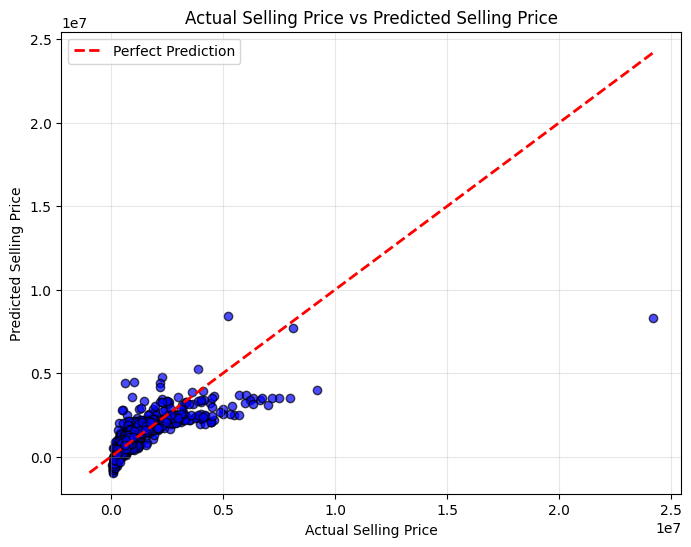

In [27]:
# ==========================================
# TASK 19: VISUALIZE MODEL PERFORMANCE
# ==========================================

import matplotlib.pyplot as plt
import numpy as np

# Create Actual vs Predicted plot
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_test_pred,
    color="blue",
    alpha=0.7,
    edgecolor="black"
)

# Determine range for reference line
min_value = min(y_test.min(), y_test_pred.min())
max_value = max(y_test.max(), y_test_pred.max())

# Perfect prediction line
plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    color="red",
    linestyle="--",
    linewidth=2,
    label="Perfect Prediction"
)

plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.title("Actual Selling Price vs Predicted Selling Price")
plt.legend()
plt.grid(alpha=0.3)

plt.show()


### Task 20: Conclude
•
Comment on the most influential features.

•
Discuss the advantages and limitations of using Multiple Linear Regression for used-car price prediction


### Conclusion
Conclude the experiment by stating whether the Multiple Linear Regression model implemented using the OLS normal equation was able to predict used-car selling prices effectively. The conclusion should include the obtained RSS and R² values, observations regarding important features, the effect of preprocessing and feature engineering, and the limitations of using a linear regression model for real-world used-car price prediction.